In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

## calcualte the probability of detection |1>
def ideal_rabi_t(t, detune, omega):
  omg = (omega**2 + detune**2)
  term = np.sin(np.sqrt(omg)/2*t)
  return omega**2/omg*term*term

In [16]:
def plot_rabi(x, y, y_error, fit = False, fit_x = [], fit_y = []):
  """Calculates the sum of each row in the matrix and plots the values.
  """

  # Create the plot
  plt.figure(figsize=(8, 4))

  if fit:
    plt.plot(fit_x, fit_y, color="cyan", label="Fitted curve")
  plt.errorbar(
      x,
      y,
      yerr=y_error,
      marker=".",
      color="b",
      ecolor="r",  # Red color for error bars
      elinewidth=1.5,
      capsize=2,  # Adds caps to the error bars
      linewidth=2,
      ls="none",  # Removes the connecting line between points
      label = "averaged data"
  )

  plt.title("Rabi flopping over time")
  plt.xlabel("Coherent drive time (s)")
  plt.ylabel("Photon count")
  plt.grid(True, linestyle="--", alpha=0.6)
  plt.legend()
  plt.show()


def generate_mock_rabi_data(x, n_time_data, n_shots, noise_std = 0, seed = 0):
    # Initialize the matrix
    matrix = np.zeros((n_time_data, n_shots), dtype=int)

    seed = np.random.seed(seed)
    for time_data in range(n_time_data):
        col_mean = 5*np.sin(x[time_data])*np.sin(x[time_data])
        # Generate random white noise from a normal distribution (mean=0, std=noise_std)
        noise = np.random.normal(loc=0.0, scale=noise_std, size=n_shots)
        col_noisy = col_mean + noise
        col_noisy = [x if x > 0 else 0 for x in col_noisy] # ensure no negative value
        matrix[time_data, :] = col_noisy

    # Display the matrix and verification
    return matrix 

def fit_rabi_plot(x_data, y_data, initial_guesses):
    def model_func(x, omega, detune):
      omg = (omega**2 + detune**2)
      sin2 = np.sin(np.sqrt(omg)/2*x)*np.sin(np.sqrt(omg)/2*x)
      return 5*(omega**2/omg)*sin2

    popt, pcov = curve_fit(model_func, x_data, y_data, p0=initial_guesses)
    print("Optimized parameters (rabi freq Hz, detuning Hz):", popt)

    x_fit = np.linspace(min(x_data), max(x_data), 100)
    y_fit = model_func(x_fit, *popt)

    return x_fit, y_fit

n_time_data 100
n_shots 1000
noise_std 2
average photon error count:  0.051088217336290154
Optimized parameters (rabi freq Hz, detuning Hz): [2.00025327 0.        ]


C:\Users\Lana\AppData\Local\Temp\ipykernel_11404\4260591744.py:54: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(model_func, x_data, y_data, p0=initial_guesses)


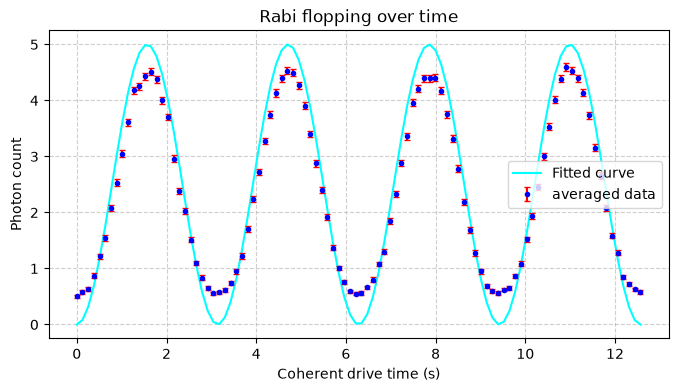

In [21]:
###################################################
# Set parameters to generate mock data
n_time_data = 100
n_shots = 1000
noise_std = 2
print("n_time_data", n_time_data)
print("n_shots", n_shots)
print("noise_std", noise_std)

time_val = np.linspace(0, 4 * np.pi, n_time_data) # Generate n_time_data evenly spaced points from 0 to 4*pi
matrix = generate_mock_rabi_data(time_val, n_time_data, n_shots, noise_std = noise_std)
# print("time_val", time_val)
# print("Mock Data Matrix:", matrix)

###################################################
# extract information from mock data
averaged_photon_count = np.sum(matrix, axis=1) / matrix.shape[1] # for each time_val

# Calculate standard error across each row
  # Standard Deviation with Bassel correction / sqrt(number of shots)
errors_photon_count = np.std(matrix, axis = 1, ddof=1) / np.sqrt(matrix.shape[1])
print("average photon error count: ", np.sum(errors_photon_count)/len(errors_photon_count))
# print("averaged_photon_count:", averaged_photon_count) 
# print("row_errors", errors_photon_count)

###################################################
# compute fit function
initial_guesses = [2, 0] # rabi frequency, detuning

fit_x, fit_y = fit_rabi_plot(
    x_data = time_val, 
    y_data = averaged_photon_count,
    initial_guesses = initial_guesses)

###################################################
plot_rabi(
    x = time_val,
    y = averaged_photon_count, 
    y_error = errors_photon_count, 
    fit=True, fit_x = fit_x, fit_y = fit_y)
